# IMPORTS

In [1]:
from pathlib import Path 
from PIL import Image

import json
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np
import matplotlib.patches as patches

# 1. INTRODUCTION

The **SeaDronesSee** dataset [[1]](#ref-1) includes footage from different UAVs in SAR missions in the maritime environment. During this notebook we will perform an EDA on it, to learn the dataset nuances in detail. 

## 1.1 Import & Loading Datasets

In [2]:
DATA_FOLDER = Path(r"../../data/SeaDronesSee_MOT")

# Annotations
ANNOTATIONS_FOLDER = DATA_FOLDER / "annotations"
TRAIN_ANNOTATIONS = ANNOTATIONS_FOLDER / "instances_train_objects_in_water.json"
VAL_ANNOTATIONS = ANNOTATIONS_FOLDER / "instances_val_objects_in_water.json"
TEST_ANNOTATIONS = ANNOTATIONS_FOLDER / "instances_test_objects_in_water.json"

# Images
IMG_FOLDER = DATA_FOLDER / "SeaDronesSee_MOT_jpg_compressed/Compressed"
TRAIN_IMG_FOLDER = IMG_FOLDER / "train"
VAL_IMG_FOLDER = IMG_FOLDER / "val"
TEST_IMG_FOLDER = IMG_FOLDER / "test"


In [3]:
with TRAIN_ANNOTATIONS.open("r", encoding="utf-8") as file: 
    train_annotations = json.load(file)

with VAL_ANNOTATIONS.open("r", encoding="utf-8") as file: 
    val_annotations = json.load(file)

with TEST_ANNOTATIONS.open("r", encoding="utf-8") as file: 
    test_annotations = json.load(file)

## 1.2 Brief Inspection

In [4]:
train_annotations

{'info': {'year': '2021',
  'version': '1',
  'description': '',
  'contributor': '',
  'url': 'localhost',
  'date_created': '2021-03-10T16:59:51.049774'},
 'licenses': [{'id': 1, 'url': '', 'name': 'Unknown'}],
 'categories': [{'supercategory': 'person', 'id': 1, 'name': 'swimmer'},
  {'supercategory': 'person', 'id': 2, 'name': 'swimmer with life jacket'},
  {'supercategory': 'boat', 'id': 3, 'name': 'boat'},
  {'supercategory': 'lifejacket', 'id': 6, 'name': 'life jacket'}],
 'images': [{'id': 0,
   'file_name': '0.png',
   'height': 2160,
   'width': 3840,
   'source': {'drone': 'mavic',
    'folder_name': 'DJI_0057',
    'video': 'DJI_0057.MP4',
    'frame_no': 0},
   'video_id': 0,
   'frame_index': 0,
   'date_time': '2020-08-27T14:18:12',
   'meta': {'date_time': '2020-08-27T12:18:12',
    'gps_latitude': 47.671755,
    'gps_latitude_ref': 'N',
    'gps_longitude': 9.269907,
    'gps_longitude_ref': 'E',
    'altitude': 11.299448948491314,
    'gimbal_pitch': 45.4,
    'compas

In [5]:
train_images = pd.DataFrame(train_annotations["images"])
val_images = pd.DataFrame(val_annotations["images"])
test_images = pd.DataFrame(test_annotations["images"])

train_length = len(train_images)
val_length = len(val_images)
test_length = len(test_images)
total_length = train_length + val_length + test_length

print(
    f"Total number of images: {total_length}\n"
    f"  - Train images: {train_length} ({train_length/total_length * 100:.2f}%)\n"
    f"  - Validation images: {val_length} ({val_length/total_length * 100:.2f}%)\n"
    f"  - Test images: {test_length} ({test_length/total_length * 100:.2f}%)\n"
)

Total number of images: 54096
  - Train images: 27259 (50.39%)
  - Validation images: 8584 (15.87%)
  - Test images: 18253 (33.74%)



We see that we have a train, validation and test sets totaling more than 54,000 images. We also observe how the annotations are structured in a json format with different metadata between for each frame. 

# 2. ANALYSIS

## 2.1 Metadata

In [6]:
train_meta = pd.json_normalize(train_images["meta"])
val_meta = pd.json_normalize(val_images["meta"])
test_meta = pd.json_normalize(test_images["meta"])

train_meta.head()

,date_time,gps_latitude,gps_latitude_ref,gps_longitude,gps_longitude_ref,altitude,gimbal_pitch,compass_heading,gimbal_heading,speed,xspeed,yspeed,zspeed
0,2020-08-27T12:18:12,47.671755,N,9.269907,E,11.299449,45.4,319.3,322.4,2.342937,1.799952,-1.499960,0.0
1,2020-08-27T12:18:12,47.671756,N,9.269906,E,11.299449,45.4,319.4,322.4,2.701928,2.099944,-1.699954,0.0
2,2020-08-27T12:18:12,47.671756,N,9.269906,E,11.299449,45.4,319.4,322.4,2.701928,2.099944,-1.699954,0.0
3,2020-08-27T12:18:12,47.671756,N,9.269906,E,11.299449,45.4,319.4,322.4,2.701928,2.099944,-1.699954,0.0
4,2020-08-27T12:18:12,47.671759,N,9.269903,E,11.199454,45.4,319.4,322.4,2.982920,2.299938,-1.899949,0.0


We observe how for each image we have different continuous metadata terms with respect to the GPS and the speed of the drone. More importantly, we also have the **gimbal pitch** and **altitude** continuously for every frame, which is one of the strengths of this dataset. On the analysis we will omit the GPS variables as we consider there is no valuable information in them for the task at hand, since the shots were all captured in the same lake. 

In [7]:
def get_drone_type(videos):
    """Obtain the drone the video was shot by in a separate column."""
    parts = videos["name:"].str.split("/").str
    drone = parts[-2]
    name = parts[-1]

    videos = videos.drop(columns=["name:"])
    videos["drone"] = drone
    videos["name"] = name

    return videos


train_videos = pd.DataFrame(train_annotations["videos"])
val_videos = pd.DataFrame(val_annotations["videos"])
test_videos = pd.DataFrame(test_annotations["videos"])

train_videos = get_drone_type(train_videos)
val_videos = get_drone_type(val_videos)
test_videos = get_drone_type(test_videos)

train_videos.head()

,id,height,width,drone,name
0,0,2160,3840,mavic,DJI_0057.MP4
1,1,2160,3840,mavic,DJI_0055.MP4
2,2,2160,3840,mavic,DJI_0039.MP4
3,4,2160,3840,mavic,DJI_0063.MP4
4,5,2160,3840,mavic,DJI_0065.MP4


In [8]:
print(
    f"Train set drones: {train_videos['drone'].unique().tolist()}\n"
    f"Validation set drones: {val_videos['drone'].unique().tolist()}\n"
    f"Test set drones: {test_videos['drone'].unique().tolist()}\n"
)


Train set drones: ['mavic', 'm210', 'm100']
Validation set drones: ['mavic', 'm210', 'm100']
Test set drones: ['mavic', 'm210', 'm100']



From the SeaDronesSee paper, we note that the footage was taken by three cameras:

    - Hasselblad L1D-20c
    - Zenmuse X5
    - Zenmuse XT2

We also obtain from the paper how it was taken from four different drones, of which in our dataset we only have the following: 

    - DJI Matrice 100
    - DJI Matrice 210
    - DJI Mavic 2 Pro

These are very important parameters, as by knowing the characteristics of the camera every image was shot from, as well as the altitude and pitch, we could determine the distance from an object to the camera. We see that we have different drones associated with each video, but on the paper we do not have a direct relation between camera and drone. Thus, we do have to do some research to make this relation.

From the FAQ section in [[2]](#ref-2) we see that the only compatible drone of the list with the Zenmuse X5 is the DJI Matrice 100. We can also see from [[3]](#ref-3), how the Zenmuse XT2 can only be mounted on any drone of the M200 series and the M600 Pro. Finally from [[4]](#ref-4) we know that the Hasselblad L1D-20c comes premounted on the Mavic 2 Pro and that it cannot be swapped from it. Thus, we obtain the following one to one relation between drones and cameras: 

    - DJI Matrice 100: Zenmuse X5
    - DJI Matrice 210: Zenmuse XT2
    - DJI Mavic 2 Pro: Hasselblad L1D-20c

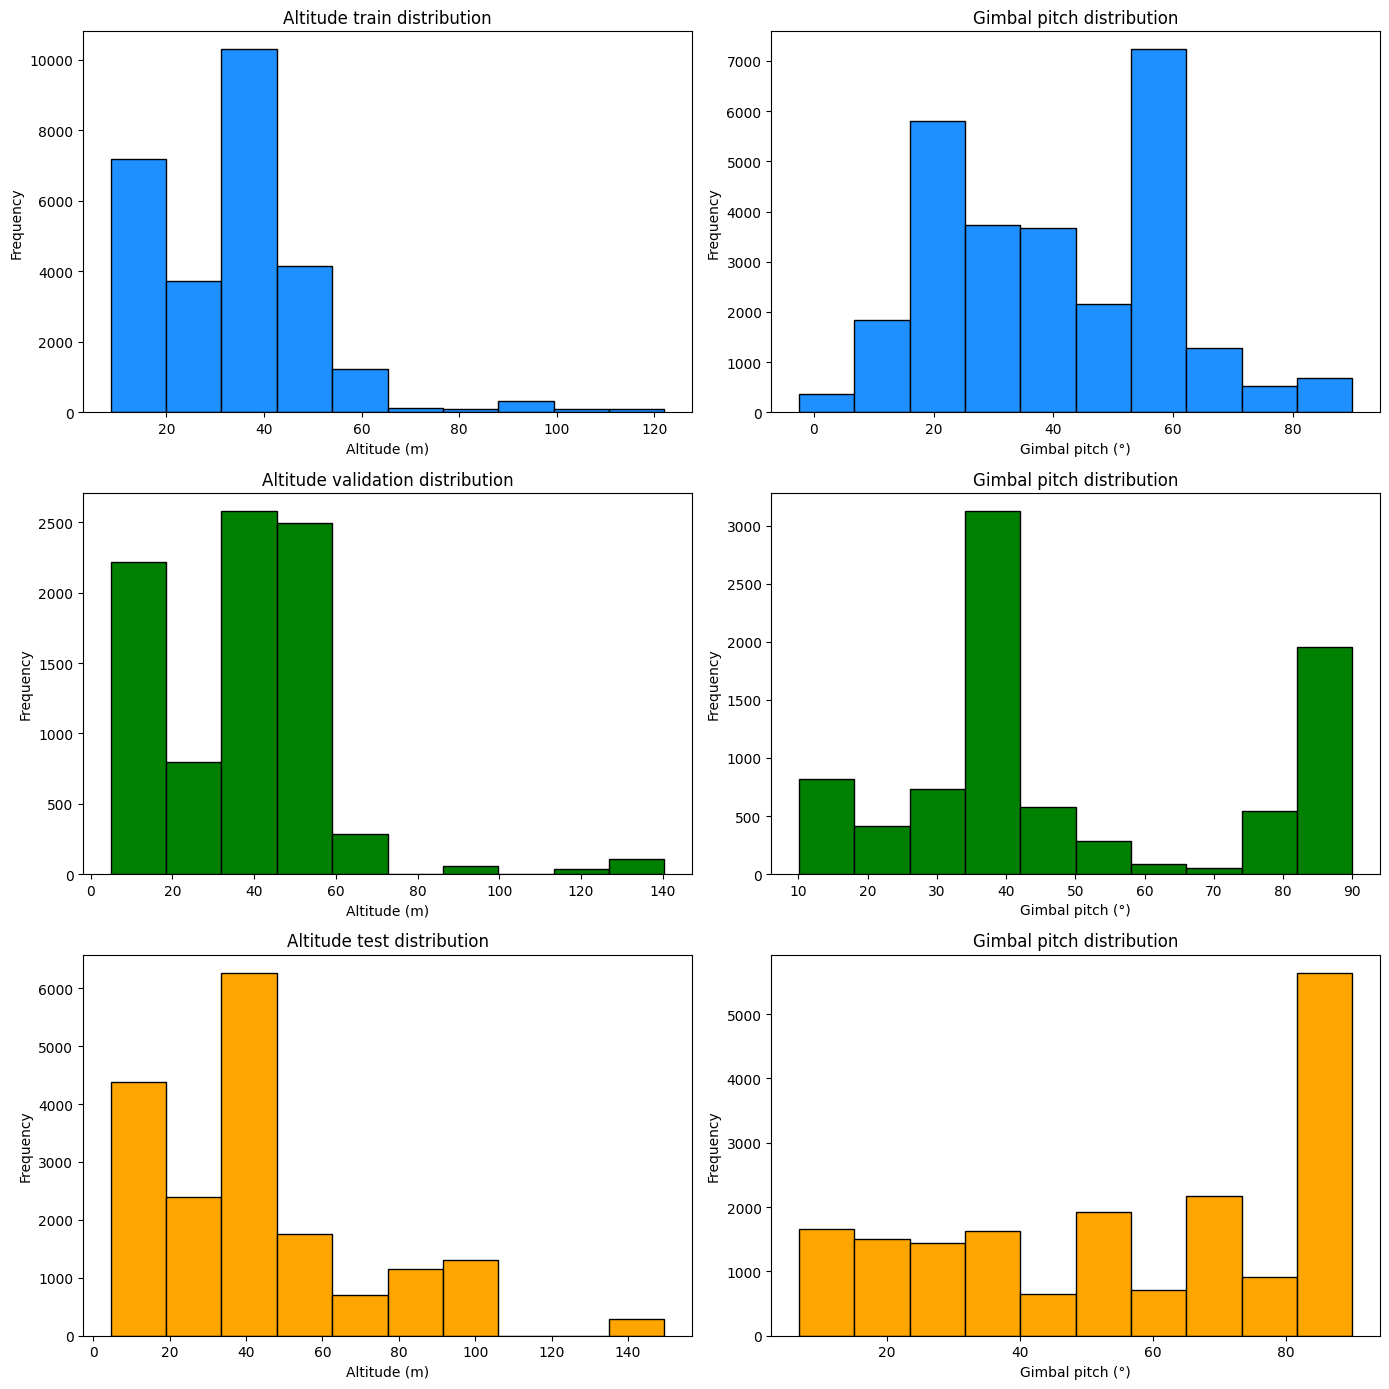

In [9]:
# Showing altitude and pitch distributions
meta = {"train": train_meta, "validation": val_meta, "test": test_meta}
colors = ["dodgerblue", "green", "orange"]

fig, ax = plt.subplots(3, 2, figsize=(14, 14))

for row, (key, df) in enumerate(meta.items()):
    ax[row, 0].hist(meta[key]["altitude"], bins=10, edgecolor="black", color=colors[row])
    ax[row, 0].set_title(f"Altitude {key} distribution")
    ax[row, 0].set_xlabel("Altitude (m)")
    ax[row, 0].set_ylabel("Frequency")

    ax[row, 1].hist(meta[key]["gimbal_pitch"], bins=10, edgecolor="black", color=colors[row])
    ax[row, 1].set_title("Gimbal pitch distribution")
    ax[row, 1].set_xlabel("Gimbal pitch (°)")
    ax[row, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

We can see how for all sets, the drone altitude mainly conentrates between **0-60m**, with really few examples of altitudes above 100 m. For the pitch we can see how it varies across sets, with a most images between 20-60° on the training set, a more uneven distribution in the validation set, and a large amount of the test being zenithal shots (90° pitch).

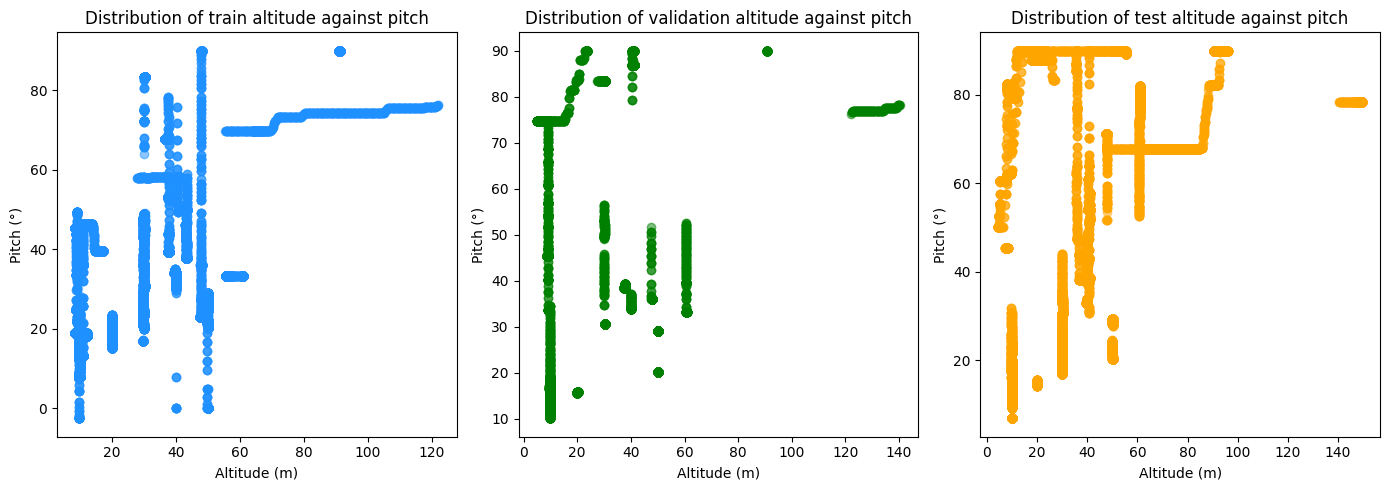

In [10]:
# Showing altitude against pitch distributions

fig, ax = plt.subplots(1, 3, figsize=(14, 5))

for col, (key, df) in enumerate(meta.items()):
    ax[col].scatter(meta[key]["altitude"], meta[key]["gimbal_pitch"], alpha=0.5, color=colors[col])
    ax[col].set_title(f"Distribution of {key} altitude against pitch")
    ax[col].set_xlabel("Altitude (m)")
    ax[col].set_ylabel("Pitch (°)")

plt.tight_layout()
plt.show()

We observe how the pitch ranges are not full for all altitudes and it can be cluttered at some altitudes. After an elevation of over 60 metres, there is no variety in pitch which is probably caused by doing a small amount of runs over the 60 m line.

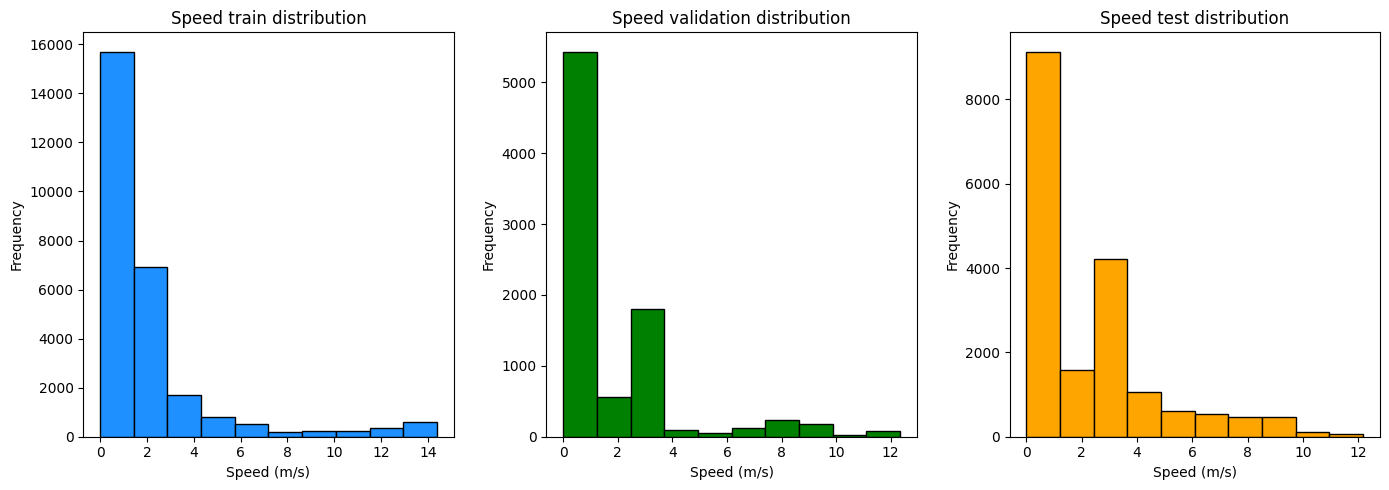

In [11]:
# Showing speed
fig, ax = plt.subplots(1, 3, figsize=(14, 5))

for col, (key, df) in enumerate(meta.items()):
    ax[col].hist(meta[key]["speed"], bins=10, edgecolor="black", color=colors[col])
    ax[col].set_title(f"Speed {key} distribution")
    ax[col].set_xlabel("Speed (m/s)")
    ax[col].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

A large amount of the shots were taken when the drone was not moving or when it was moving slowly. 

## 2.2 Objects

In [12]:
train_annotations["categories"]

[{'supercategory': 'person', 'id': 1, 'name': 'swimmer'},
 {'supercategory': 'person', 'id': 2, 'name': 'swimmer with life jacket'},
 {'supercategory': 'boat', 'id': 3, 'name': 'boat'},
 {'supercategory': 'lifejacket', 'id': 6, 'name': 'life jacket'}]

The dataset contains 4 different categories: 

- swimmer (person)
- swimmer with life jacket (person)
-  boat
- life jacket

There are **no details for each object**, which is a big downside to this dataset if we want to use open vocabulary models later on, as assessing their zero-shot ability might be difficult.

In [13]:
objects_train = pd.DataFrame(train_annotations["annotations"])
objects_train.head()

,id,image_id,bbox,area,category_id,video_id,track_id
0,0,0,"[1783, 1079, 186, 249]",46314,2,0,0
1,1,0,"[1547, 694, 271, 175]",47425,2,0,1
2,2,0,"[1811, 367, 129, 162]",20898,2,0,2
3,3,0,"[1588, 360, 122, 229]",27938,1,0,3
4,4,0,"[3386, 75, 221, 82]",18122,2,0,4


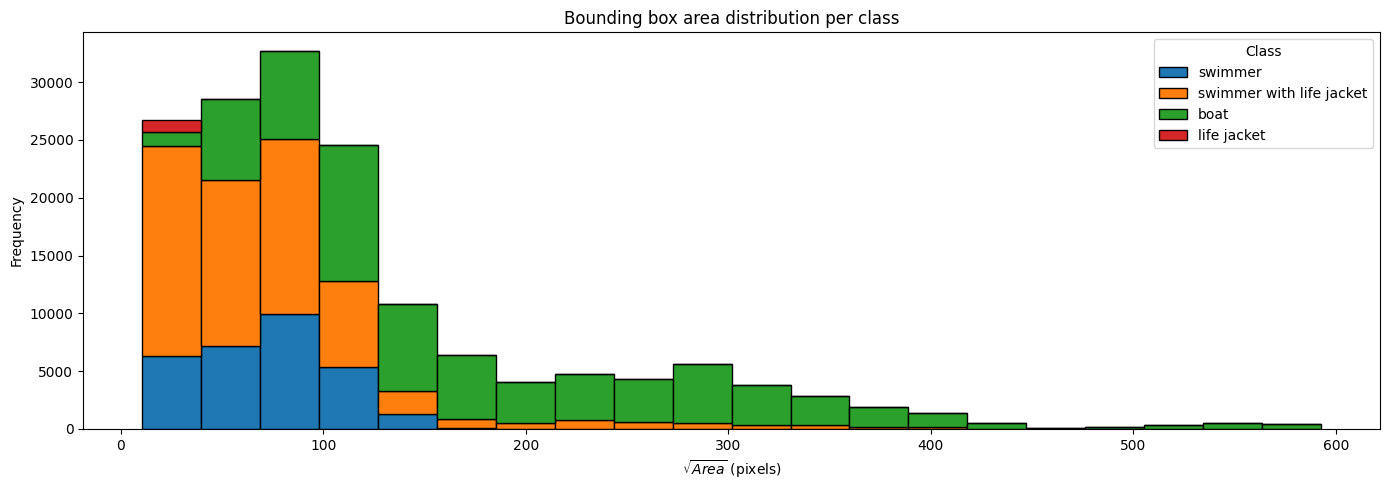

In [14]:
class_names = {
    1: "swimmer",
    2: "swimmer with life jacket",
    3: "boat",
    6: "life jacket"
}

# Plot distribution of pixel areas
fig, ax = plt.subplots(figsize=(14, 5))

classes = sorted(objects_train["category_id"].unique())
area = [np.sqrt(objects_train.loc[objects_train["category_id"] == c, "area"])
        for c in classes]

ax.hist(area, bins=20, stacked=True, 
        label=[class_names.get(c, str(c)) for c in classes], 
        edgecolor="black")
ax.set_title("Bounding box area distribution per class")
ax.set_xlabel(r"$\sqrt{Area}$ (pixels)")
ax.set_ylabel("Frequency")
ax.legend(title="Class", )

plt.tight_layout()
plt.show()

All of the lifejackets have a really small bounding box, while boats are by far the largest and have a relatively uniform distribution. As for the class person, we see how there are more swimmers with life jacket than regular swimmers, and the bare swimmer class is tighter. 

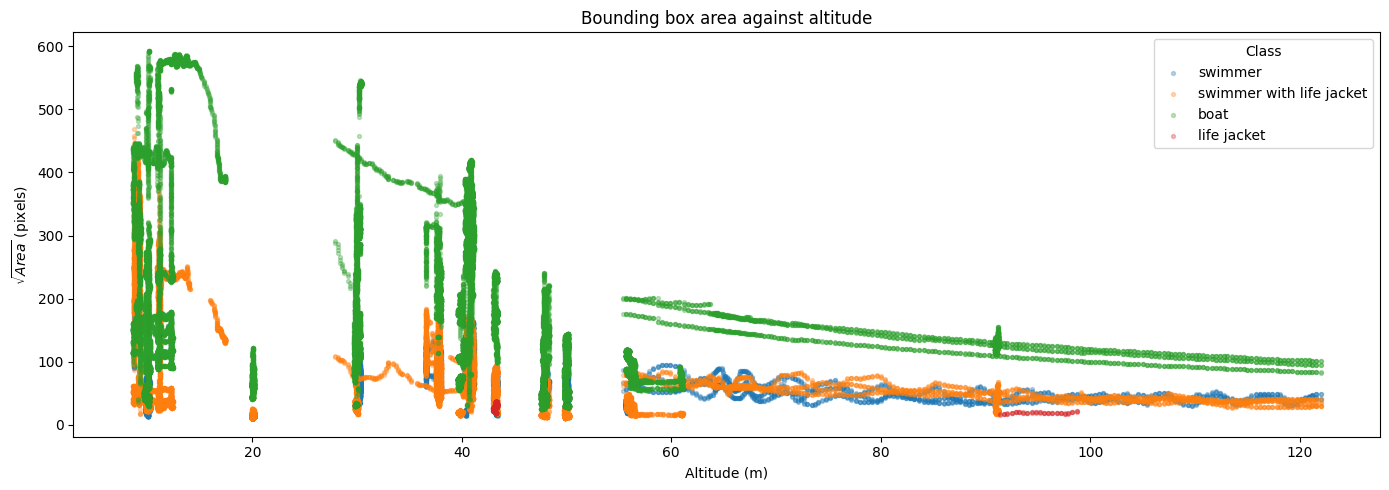

In [15]:
altitude_by_image = pd.Series(train_meta["altitude"].values, index=train_images["id"])
objects_train["altitude"] = objects_train["image_id"].map(altitude_by_image)

# Plot bounding box area against altitude
fig, ax = plt.subplots(figsize=(14, 5))

for c in sorted(objects_train["category_id"].unique()):
    sub = objects_train[objects_train["category_id"] == c]
    ax.scatter(sub["altitude"], np.sqrt(sub["area"]), s=8, alpha=0.3, label=class_names.get(c, str(c)))

ax.set_title("Bounding box area against altitude")
ax.set_xlabel("Altitude (m)")
ax.set_ylabel(r"$\sqrt{Area}$ (pixels)")
ax.legend(title="Class", )

plt.tight_layout()
plt.show()

We observe how there are some gaps in the altitude. We also observe a lot of horizontal stacks, meaning that altitude alone is not sufficient to explain the variability in bounding box size, needing the pitch and object's position too. We again observe how boats have the largest area, and how the swimmer with life jacket is distributed along many altitudes compared to the regular swimmer.

## 2.3 Images

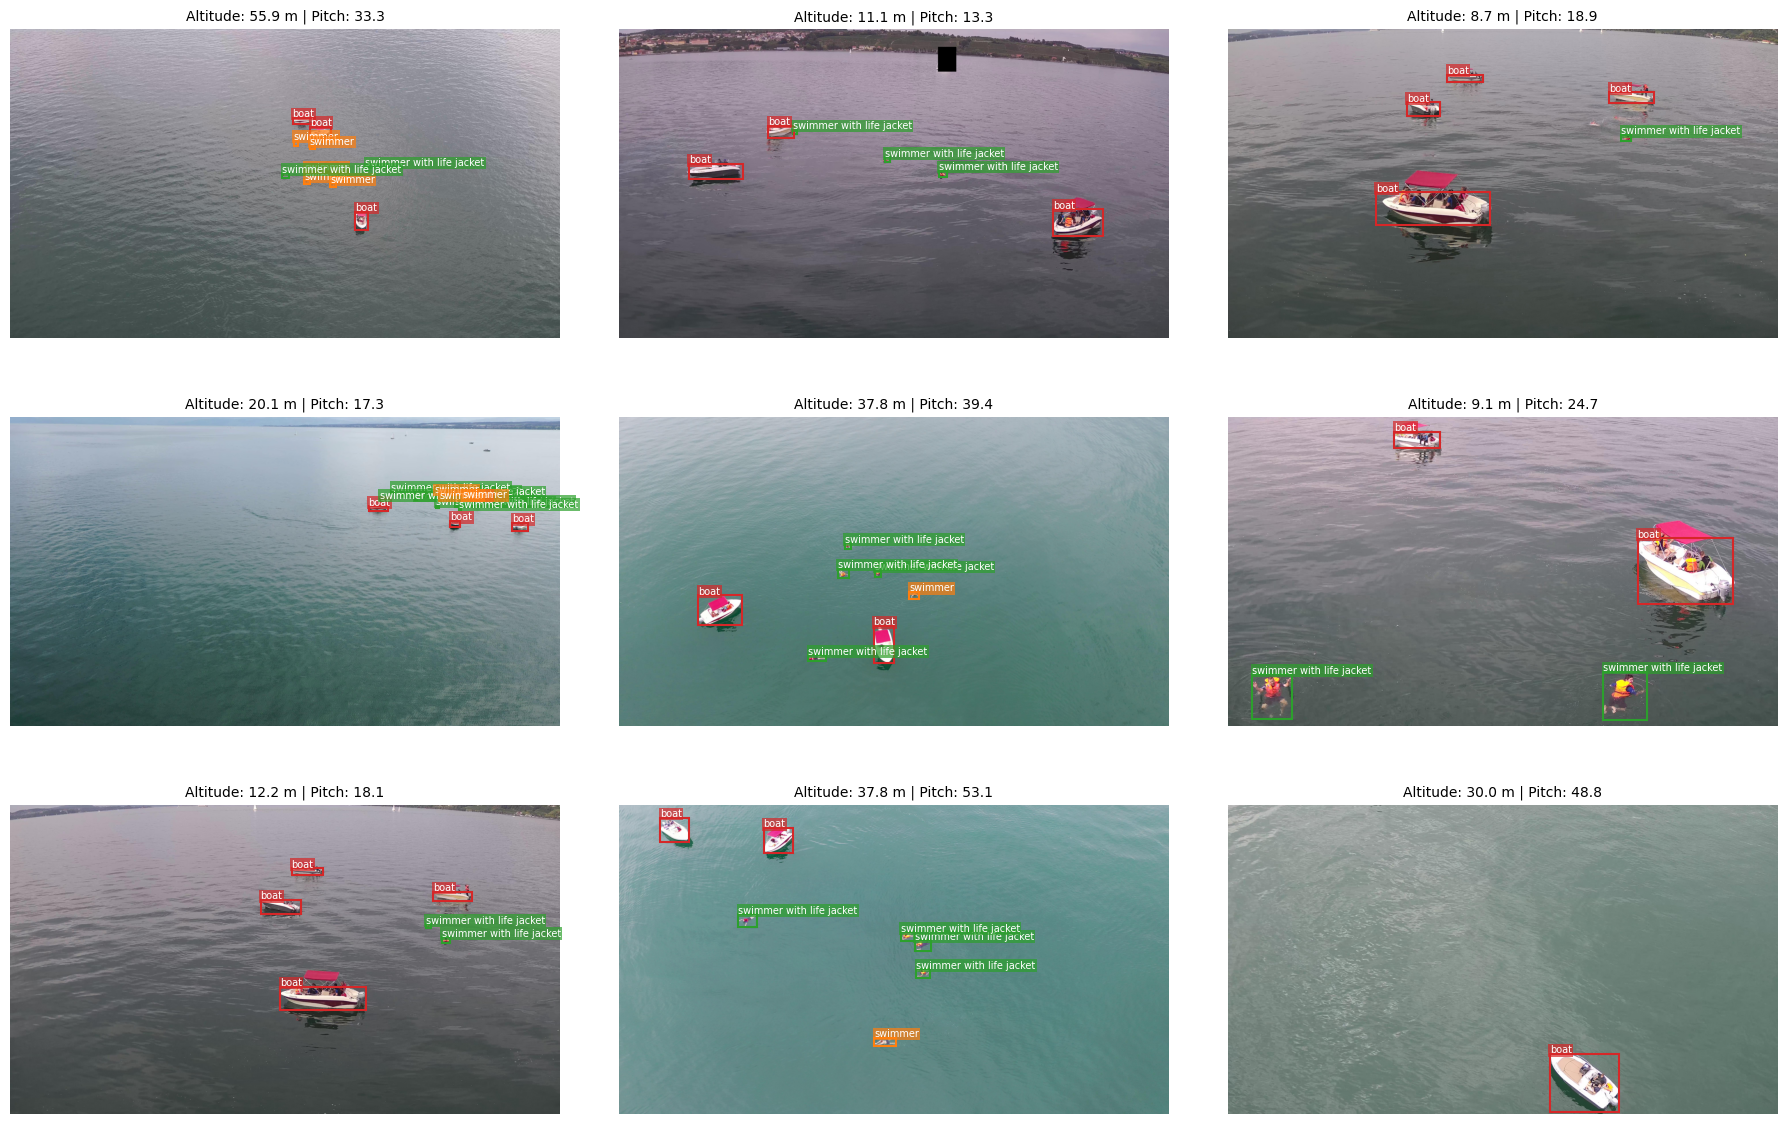

In [16]:
# Plot (3x3) grid of images
N = 9
sample = train_images.assign(
    altitude=train_meta["altitude"].values,
    pitch = train_meta["gimbal_pitch"].values
).sample(N, random_state=41)

colors = plt.cm.tab10.colors
fig, axes = plt.subplots(3, 3, figsize=(18, 12))

for ax, (_, img) in zip(axes.flat, sample.iterrows()):
    # Plot image
    path = (TRAIN_IMG_FOLDER / img["file_name"]).with_suffix(".jpg")
    ax.imshow(Image.open(path))

    # Add bounding boxes
    for _, obj in objects_train[objects_train["image_id"] == img["id"]].iterrows():
        x, y, w, h = obj["bbox"]
        color = colors[obj["category_id"] % len(colors)]
        ax.add_patch(patches.Rectangle((x, y), w, h, linewidth=1.5, edgecolor=color, facecolor="none"))
        ax.text(x, y - 5, class_names.get(obj["category_id"], str(obj["category_id"])), 
                color="white", fontsize=7, bbox=dict(facecolor=color, alpha=0.7, pad=1, edgecolor="none"))
    
    ax.set_title(f"Altitude: {img['altitude']:.1f} m | Pitch: {img['pitch']:.1f}", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

We see how the dataset is in fact fully maritime showing us swimmers with and without life jackets, as well as boats. We observe the varying altitudes and how the objects get smaller specially as the pitch angle gets smaller since they are more in the horizon, even when we have comparable heights. Finally, the boat is ridden by people, which might become problematic when testing models, because of this a second step with an open vocabulary model with the input swimmer might be key for performance.

# 3. GEOMETRIC ANALYSIS

As we have discussed associating object size with altitude is ill-conditioned, thus the creation of a metric like distance to the object is key for better model analysis later on. The key about this dataset is that we have different metadata that allows us to make this approximate calculation. 

## 3.1 Pixel focal lengths

First we need to calculate the focal length in pixels of each of the cameras. For this we will use the following: 

$$
\tan \left( \frac{\text{HFOV}}{2} \right) = \frac{w/2}{f}
$$

where $\text{HFOV}$ is the horizontal field of view, $w$ is the sensor's witdh and $f$ is the focal length.
We can then relate the focal length in mm $f$, with the focal length in pixels $f_{px}$ by using the resolution width in pixels $W$: 

$$
f_{px} = \frac{W}{w}f = \frac{W/2}{\tan \left( \frac{\text{HFOV}}{2} \right)}
$$

We can test the calculations when they give us the diagonal field of view $\text{DFOV}$ on the spec sheets by using the very first formula: 

$$
\tan \left( \frac{\text{DFOV}}{2} \right) = \frac{\frac{\sqrt{w^2 + h^2}}{2}}{f}
$$

We assume that for all cameras their 3840x2160 p resolution uses the full sensor width.

**Zenmuse X5**

From [[2]](#ref-2), we see that the sensor size is 17.3 x 13.0 mm. The focal length of the lens is 15 mm. The diagonal FOV is 72 degrees. Finally there is a distortion of 0.40% which we consider small enough to not include in our calculations. Thus, we calculate the focal length in pixels: 

$$
f_{px} = \frac{W}{w}f =  \frac{3840}{17.3} \cdot 15 \approx \boxed{3329.5 \text{px}}
$$

We check our result against the 72 degree diagonal FOV provided: 

$$
\text{DFOV} = 2 \arctan \left( \frac{\sqrt{w^2 + h^2}}{2f} \right) = 2 \arctan \left( \frac{\sqrt{17.3^2 + 13^2}}{2 \cdot 15} \right) \approx 71.61° \approx 72°
$$

Since the calculations give us a diagonal field of view close enough to the one provided in the spec. sheets, we trust the metrics provided and thus the result. 

**Zenmuse XT2**

From [[3]](#ref-3) we see that the sensor size is 1/1.7" CMOS, meaning 7.6 x 5.7 mm. The FOV is 57.12 x 42.44 degrees. No distortion value is specified. We now calculate the focal distance:

$$
f = \frac{w}{2 \tan(\text{HFOV}/2)} = \frac{7.6}{2 \tan(\text{57.12}/2)} \approx 6.98 \text{mm}
$$

There is a provided focal distance of 8 mm, so we will calculate the focal distance in pixels with both results: 

$$
f_{px} = \frac{W}{w}f =  \frac{3840}{7.6} \cdot 6.98 \approx \boxed{3526.7 \text{px}}
$$

$$
f_{px} = \frac{W}{w}f =  \frac{3840}{7.6} \cdot 8 \approx \boxed{4042.1 \text{px}}
$$

We see the values differ significantly, so we will have to come up with a strategy to see which one is more trustworthy.

**Hasselblad L1D-20c**

From [[4]](#ref-4), we see that the sensor size is 1" CMOS, meaning 13.2 x 8.8 mm. The lens is 28 mm (35 mm-equivalent). The diagonal FOV is "about 77 degrees". No distortion value is specified, so we will consider it small enough to not be included in our calculations. 

We first calculate the real focal length with the crop factor. The 35 mm, is the old film format with a useful image area of 36 x 24 mm (full frame), whose diagonal is given by: 

$$
d_{FF} = \sqrt{36^2+24^2} \approx 43.27 \text{mm}
$$

The crop factor compared to the sensor's dimensions is: 

$$
\text{crop} = \frac{d_{FF}}{d_{sensor}} = \frac{43.27}{\sqrt{13.2^2+8.8^2}} \approx 2.73 
$$

The focal length is not given for the camera, but the equivalent focal length on the 36 x 24 mm camera would need to produce the same FOV, which depends only on the ratio of $d/f$, so they both must have the same ratio: 

$$
\frac{d_{sensor}}{f_{real}} = \frac{d_{FF}}{f_{eq}} \Rightarrow f_{real} = \frac{f_{eq}}{\text{crop}} = \frac{28}{\text{2.73}} \approx 10.26 \text{mm}
$$

Thus, we can calculate the focal length in pixels: 

$$
f_{px} = \frac{W}{w}f =  \frac{3840}{13.2} \cdot 10.26 \approx \boxed{2984.7 \text{px}}
$$

We check our result against the "about 77 degrees" diagonal FOV provided: 

$$
\text{DFOV} = 2 \arctan \left( \frac{\sqrt{w^2 + h^2}}{2f} \right) = 2 \arctan \left( \frac{\sqrt{13.2^2 + 8.8^2}}{2 \cdot 10.26} \right) \approx 75.42° \approx 77°
$$

The calculations give us a diagonal field of view close enough to the one provided in the spec, as some distortion or other factors could be happening. Thus, we trust the metrics provided and therefore the result. 

In [17]:
# Calculated focal lengths in pixels by drone
F_PX = {
    "m100": 3329.5,
    "m210": [3526.7, 4042.1],  # two candidates
    "mavic": 2984.7
}

## 3.2 Coordinate changes

It is important to define our coordinate system before we can do any calculations. We use the standard pinhole convention of [[5]](#ref-5):

- Image: $u$ (right), $v$ (down), in pixels
- Camera: $x$ (right), $y$ (down), $z$ (forward along optical axis)
- World: $X$ (right), $Y$ (forward and horizontal), $Z$ (up), in metres

We also define the principal point $(c_x, c_y)$, which in our case is the center of the image in pixels.

As explained in [[5]](#ref-5), for a pinhole camera, given a point in the real world $(X,Y,Z)$ we obtain its projection in the image plane: 

$$
(X,Y,Z) \mapsto \left( f \frac{X}{Z}, f \frac{Y}{Z} \right)
$$

Since the coordinates of the images are at the top-left, we need to add the principal point offset to the calibration matrix defined in [[5]](#ref-5):

$$
K = 
\begin{bmatrix}
f_{px} &  & c_x \\
 & f_{px} & c_y \\
 &  & 1
\end{bmatrix}
\quad \Rightarrow \quad
\begin{bmatrix} 
u \\ v \\ 1  
\end{bmatrix}
\sim
K
\begin{bmatrix} 
X/Z \\ Y/Z \\ 1
\end{bmatrix}
$$

In order to change between coordinate frames: 

**Pixel to ray in the camera frame**

$$
\mathbf{d_{cam}} = K ^ {-1}  
\begin{bmatrix} 
\hat{u} \\ \hat{v} \\ 1  
\end{bmatrix}=
\begin{bmatrix} 
x \\ y \\ 1  
\end{bmatrix}
$$

, where: 

$$
x = \frac{\hat{u} - c_x}{f_{px}}, \quad y = \frac{\hat{v} - c_y}{f_{px}}
$$

The angle between the ray and the optical axis is thus: 

$$
\tan{\psi} = \sqrt{x^2 + y^2}
$$


**Camera frame to world frame**

Since a camera looking forward has $x$ along $X$, $y$ along $-Z$, and $z$ along $Y$. If we pitch it down by the pitch, $\theta$, we rotate the $y$ and $z$ axes in the vertical plane: 

$$
\mathbf{d_{world}} = 
\begin{bmatrix}
1 &  & \\
 & -\sin{\theta} & \cos{\theta} \\
 & -\cos{\theta} & -\sin{\theta}
\end{bmatrix}
\begin{bmatrix} 
x \\ y \\ 1  
\end{bmatrix} =
\begin{bmatrix} 
x \\
\cos{\theta}-y\sin{\theta} \\
-\sin{\theta}-y\cos{\theta}  
\end{bmatrix}
$$

**Depression angle**

It is the angle of the ray below the horizontal: 

$$
\sin{\alpha} = \frac{\sin{\theta}+y\cos{\theta}}{\sqrt{1+x^2+y^2}}
$$

In [18]:
# image size and principal point in pixels
W, H = 3840, 2160
CENTER = [W/2, H/2]

In [19]:
def pixel_to_camera(d_pixel: np.ndarray, f_px) -> np.ndarray: 
    """
    Changes a homogenous pixel [u, v, 1] to the ray in the camera frame
    """
    K = np.ndarray(
        [f_px, 0, CENTER[0]],
        [0, f_px, CENTER[1]],
        [0, 0, 1]
    )
    d_cam = np.linalg.inv(K) @ d_pixel

    return d_cam


def camera_to_world(d_cam: np.ndarray, pitch) -> np.ndarray: 
    """
    Changes a rau from the camera frame to the world
    """
    theta = np.deg2rad(pitch)  # convert pitch to radians
    R = np.ndarray(
        [1, 0, 0],
        [0, -np.sin(theta), np.cos(theta)],
        [0, -np.cos(theta), -np.sin(theta)]
    )
    d_world = R @ d_cam

    return d_world


def pixel_to_world(d_pixel: np.ndarray, f_px, pitch) -> np.ndarray:
    """
    Changes a homogenous pixel [u, v, 1] to a ray in the world
    """
    d_cam = pixel_to_camera(d_pixel, f_px)
    d_world = camera_to_world(d_cam, pitch)

    return d_world

## 3.3 Correcting distortion

If we check a few images near the horizon line for some of the drones, we'll see that there is some radial distortion. To assess it we'll use the horizon line as a ground truth straight line to correct this distortion. Because of this, we can only measure the distortion for Zenmuse XT2 and Hasselblad L1D-20c, as they are the only drones who have footage with a low enough pitch for the horizon line to be visible. 

A real lens displaces all image points along the line through the distortion centre by a factor $L$ that depend only on the radius [[6]](#ref-6). If we use the principal point (image centre) as the centre: 

$$
x_u = x_d L(r) \\

y_u = y_d L(r) \\

L(r) = 1 + k_1 r^2, \quad r=\sqrt{x_d^2+y_d^2}
$$

, where $(x_d, y_d)$ is the measured point from the distortion centre (principal point in our case), $(x_u, y_u)$ is the undistorted point from the distortion centre, and $r$ is the distance centre (in $W/2$ units).

Let $(x_j, y_j)$ be a corrected point. To assess how good a correction coefficient, $k_1$, is, we compute the sum of squared orthogonal residuals with respect to the corrected line:

$$
\chi^2 = \sum_j e_j^2 = \sum_j \left( -(x_j - \bar{x})\sin{\varphi} + (y_j - \bar{y})\cos{\varphi} \right)^2
$$

, where $(\bar{x}, \bar{y})$ is the line's centroid, and $\varphi$ is the angle between the corrected line and the horizontal.

To get the best fitting line we neet to minimize $\chi^2$ over $\varphi$:

$$
a = \sum_j  x_j^2 - \frac{1}{n} \left( \sum_j x_j \right)^2, \quad b = \sum_j  x_jy_j - \frac{1}{n} \sum_j x_j \sum_j y_j, \quad c = \sum_j  y_j^2 - \frac{1}{n} \left( \sum_j y_j \right)^2 \\ 

\chi^2 = \sum_j e_j^2 = a \sin^2{\varphi} - 2b \sin{\varphi}\cos{\varphi} + c \cos^2{\varphi} \\

\frac{d \chi^2}{d \varphi} = (a-c)\sin{2\varphi}- 2b\cos{2\varphi} = 0 \quad \Rightarrow \quad \varphi = \frac{1}{2} \arctan 2 (2b, a-c) \quad \text{[6]}
$$

Thus, the minimum sum of residuals is: 

$$
\chi^2_{min} = \frac{1}{2} \left( (a+c) - \sqrt{(a-c)^2+4b^2} \right)
$$

Since we have different images for each drone, we minimize $k_1$ over all image horizons, obtaining the error: 

$$
E(k_1) = \sum_l \chi_{min, l}^2(k_1)
$$

Despite having different methods, to not overcomplicate the problem we will use a grid of evenly spaced trial $k_1$ and compute the the error for each of them across all frames, distinguishing by drone. With this we will obtain, a curve of errors and we'll select the correction coefficient that gives us the lowest error, checking that it is in fact a minimum. 

In [24]:
def normalize(points) -> np.ndarray: 
    """
    Pixels -> coordinates from the principal point, in W/2 units. Shape (n, 2)
    """
    return (np.asarray(points, dtype=float) - CENTER) / (W/2)


def undistort(points: np.ndarray, k1) -> np.ndarray:
    """
    Undistort a set of normalized points (n, 2) given a correction coefficient
    """
    r2 = np.sum(points**2, axis=1, keepdims=True)
    
    return points * (1 +  k1 * r2)


def calculate_residuals(points: np.ndarray, k1): 
    """
    Calculates the minimum residuals w.r.t. the best fittig line
    """
    x, y = undistort(points, k1).T
    n = len(x)
    
    a = np.sum(x**2) - np.sum(x)**2 / n
    b = np.sum(x * y) - np.sum(x) * np.sum(y) / n
    c = np.sum(y**2) - np.sum(y)**2 / n

    return 1/2 * ((a + c) - np.sqrt((a-c)**2 + 4*b**2))


def minimize_error(correction_grid, images_points):
    """
    Grid search of k1 over all the horizons of a drone
    """
    images = [normalize(points) for points in images_points]
    errors = np.array([
        sum(calculate_residuals(points, k1) for points in images)
        for k1 in correction_grid
    ])

    i_min = np.argmin(errors)
    if i_min in (0, len(correction_grid) - 1):
        print("Warning: minimum is at the edge of the grid")
    
    return correction_grid[i_min], errors

We use the annotated points of the horizon from `results/horizon_annotations.csv` to estimate the correction coefficient. 

In [25]:
horizon_annotations = pd.read_csv(Path(r"../../results/horizon_annotations.csv"))
horizon_annotations["points"] = horizon_annotations["points"].apply(json.loads)
horizon_annotations = horizon_annotations[horizon_annotations["status"] == "ok"]
horizon_annotations.head()

,split,image_id,drone,video,frame_no,pitch,altitude,points,status
1,train,32006,m210,dji_0001_d3.mov,292,9.6,49.897567,"[[8.2, 1320.1], [1254.9, 1360.1], [2473.5, 136...",ok
2,train,32009,m210,dji_0001_d3.mov,295,12.0,49.897567,"[[5.9, 1320.1], [843.3, 1355.4], [1680.7, 1357...",ok
4,train,32013,m210,dji_0001_d3.mov,299,14.5,49.897567,"[[5.9, 1317.7], [509.3, 1331.8], [1198.5, 1357...",ok
5,train,35224,m210,dji_0011_d3.mov,1509,15.3,10.999464,"[[5.9, 33.4], [154.1, 16.9], [297.6, 0.4], [26...",ok
6,test,29657,m210,dji_0001.mov,12810,16.8,29.998537,"[[8.2, 233.3], [389.3, 207.4], [822.1, 183.9],...",ok


In [26]:
correction_grid = np.linspace(-0.2, 0.3, 5001)  # 0.001 step
k1, errors = {}, {}

for drone in ["mavic", "m210"]:
    drone_points = horizon_annotations.loc[horizon_annotations["drone"] == drone, "points"]
    k1[drone], errors[drone] = minimize_error(correction_grid, drone_points)
    print(f"{drone}: k1 = {k1[drone]:.3f} ({len(drone_points)} images)")


mavic: k1 = -0.006 (39 images)
m210: k1 = 0.130 (43 images)


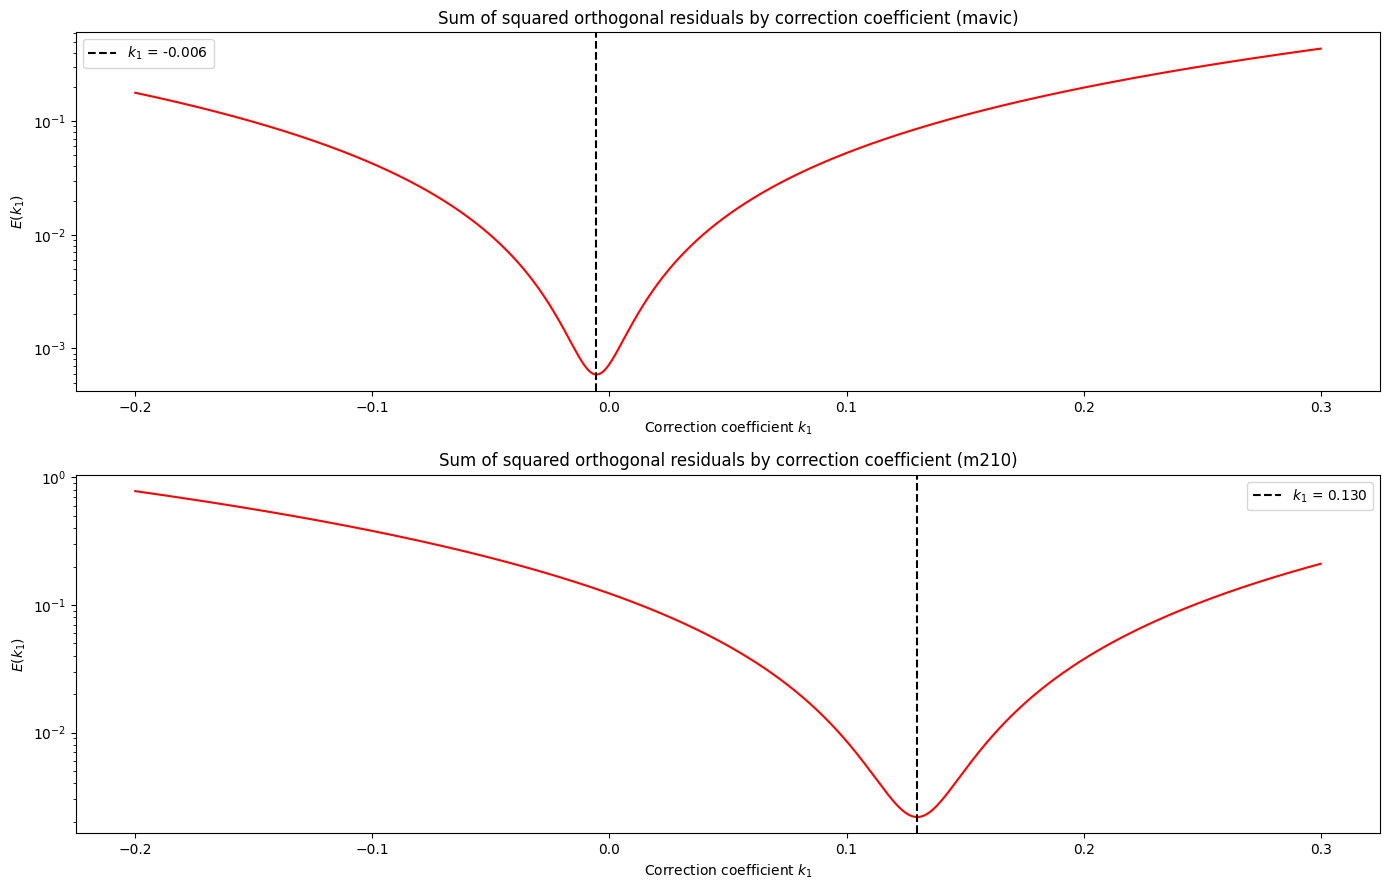

In [27]:
fig, ax = plt.subplots(2, 1, figsize=(14, 9))

for i, drone in enumerate(["mavic", "m210"]):
    ax[i].plot(correction_grid, errors[drone], color="red")
    ax[i].axvline(k1[drone], color="black", linestyle="--", label=f"$k_1$ = {k1[drone]:.3f}")
    ax[i].set_yscale("log")
    ax[i].set_title(f"Sum of squared orthogonal residuals by correction coefficient ({drone})")
    ax[i].set_xlabel("Correction coefficient $k_1$")
    ax[i].set_ylabel("$E(k_1)$")
    ax[i].legend()

plt.tight_layout()
plt.show()

We observe clear minima for both $k_1$. The one for the mavic drone is 0.006, too small for consideration (due to also the inherent noise in the manual labelling of the points). For the m210, as expected from manual inspection, the correction coefficient, 0.130, is signifacnt enogouh to be taken into account. 

## 3.4 Slant range and angle from target to drone

# REFERENCES

<a id="ref-1"></a>[1] L. A. Varga, B. Kiefer, M. Messmer, and A. Zell, "SeaDronesSee: A maritime benchmark for detecting humans in open water," in *Proc. IEEE/CVF Winter Conf. Appl. Comput. Vis. (WACV)*, 2022, pp. 2260–2270.

<a id="ref-2"></a>[2] https://www.dji.com/zenmuse-x5/info

<a id="ref-3"></a>[3] https://www.dji.com/support/product/zenmuse-xt2

<a id="ref-4"></a>[4] https://www.dji.com/mavic-2/info

<a id="ref-5"></a>[5] R. Hartley and A. Zisserman, Multiple View Geometry in Computer Vision, 2nd ed., Cambridge University Press, 2004

<a id="ref-6"></a>[6] F. Devernay and O. Faugeras, "Straight lines have to be straight," Machine Vision and Applications, 13(1), 14–24, 2001